# Task 1 — Exploratory Data Analysis

**Uber Fare Prediction | sample_50000.csv**

This notebook answers Q1–Q8, records cleaning decisions, and includes additional questions. Coordinates are converted from radians to degrees before geographic validation.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, spearmanr, pearsonr

ROOT = Path.cwd()
if not (ROOT / 'data/raw/sample_50000.csv').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'data/raw/sample_50000.csv'
raw = pd.read_csv(DATA_PATH)
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (50000, 26)


,User ID,User Name,Driver Name,Car Condition,Weather,Traffic Condition,key,fare_amount,pickup_datetime,pickup_longitude,...,month,weekday,year,jfk_dist,ewr_dist,lga_dist,sol_dist,nyc_dist,distance,bearing
0,KHVrEVlD,Kimberly Adams,Amy Butler,Very Good,windy,Congested Traffic,2009-06-15 17:26:21,4.5,2009-06-15 17:26:21,-1.288826,...,6,0,2009,20.265840,55.176046,14.342611,34.543548,27.572573,1.030764,-2.918897
1,lPxIuEri,Justin Tapia,Hannah Zimmerman,Excellent,cloudy,Flow Traffic,2010-01-05 16:52:16,16.9,2010-01-05 16:52:16,-1.291824,...,1,1,2010,44.667679,31.832358,23.130775,15.125872,8.755732,8.450134,-0.375217
2,gsVN8JLS,Elizabeth Lopez,Amanda Jackson,Bad,stormy,Congested Traffic,2011-08-18 00:35:00,5.7,2011-08-18 00:35:00,-1.291242,...,8,3,2011,43.597686,33.712082,19.865289,17.722624,9.847344,1.389525,2.599961
3,9I7kWFgd,Steven Wilson,Amy Horn,Very Good,stormy,Flow Traffic,2012-04-21 04:30:42,7.7,2012-04-21 04:30:42,-1.291319,...,4,5,2012,42.642965,32.556289,21.063132,15.738963,7.703421,2.799270,0.133905
4,8QN5ZaGN,Alexander Andrews,Cassandra Larson,Bad,stormy,Congested Traffic,2010-03-09 07:51:00,5.3,2010-03-09 07:51:00,-1.290987,...,3,1,2010,43.329953,39.406828,15.219339,23.732406,15.600745,1.999157,-0.502703


## 1. Initial audit and cleaning log

**Decision:** convert coordinate columns from radians to degrees, then exclude invalid geographic rows and non-positive fares. These are deterministic data-validity rules, not learned preprocessing.

In [17]:
COORDS = ['pickup_longitude','pickup_latitude','dropoff_longitude','dropoff_latitude']
df = raw.copy()
for col in COORDS: df[col] = np.degrees(pd.to_numeric(df[col], errors='coerce'))
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')
print('Missing cells:', int(df.isna().sum().sum()))
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Repeated keys after first:', int(df['key'].duplicated().sum()))

BOUNDS = {'lat_min':40.45,'lat_max':41.05,'lon_min':-74.30,'lon_max':-73.60}
pickup_ok = df.pickup_latitude.between(BOUNDS['lat_min'],BOUNDS['lat_max']) & df.pickup_longitude.between(BOUNDS['lon_min'],BOUNDS['lon_max'])
dropoff_ok = df.dropoff_latitude.between(BOUNDS['lat_min'],BOUNDS['lat_max']) & df.dropoff_longitude.between(BOUNDS['lon_min'],BOUNDS['lon_max'])
zero_zero = ((df.pickup_latitude==0)&(df.pickup_longitude==0)) | ((df.dropoff_latitude==0)&(df.dropoff_longitude==0))
valid = pickup_ok & dropoff_ok & ~zero_zero & df.fare_amount.gt(0) & df.pickup_datetime.notna()
df_clean = df.loc[valid].copy()
for col, vals in {'hour':df_clean.pickup_datetime.dt.hour,'day':df_clean.pickup_datetime.dt.day,'month':df_clean.pickup_datetime.dt.month,'weekday':df_clean.pickup_datetime.dt.weekday,'year':df_clean.pickup_datetime.dt.year}.items(): df_clean[col] = vals
print(f'Rows retained: {len(df_clean):,}/{len(df):,}; excluded: {(~valid).sum():,} ({(~valid).mean():.2%})')
df_clean.head()

Missing cells: 0
Exact duplicate rows: 0
Repeated keys after first: 445
Rows retained: 48,897/50,000; excluded: 1,103 (2.21%)


,User ID,User Name,Driver Name,Car Condition,Weather,Traffic Condition,key,fare_amount,pickup_datetime,pickup_longitude,...,month,weekday,year,jfk_dist,ewr_dist,lga_dist,sol_dist,nyc_dist,distance,bearing
0,KHVrEVlD,Kimberly Adams,Amy Butler,Very Good,windy,Congested Traffic,2009-06-15 17:26:21,4.5,2009-06-15 17:26:21,-73.844311,...,6,0,2009,20.265840,55.176046,14.342611,34.543548,27.572573,1.030764,-2.918897
1,lPxIuEri,Justin Tapia,Hannah Zimmerman,Excellent,cloudy,Flow Traffic,2010-01-05 16:52:16,16.9,2010-01-05 16:52:16,-74.016048,...,1,1,2010,44.667679,31.832358,23.130775,15.125872,8.755732,8.450134,-0.375217
2,gsVN8JLS,Elizabeth Lopez,Amanda Jackson,Bad,stormy,Congested Traffic,2011-08-18 00:35:00,5.7,2011-08-18 00:35:00,-73.982738,...,8,3,2011,43.597686,33.712082,19.865289,17.722624,9.847344,1.389525,2.599961
3,9I7kWFgd,Steven Wilson,Amy Horn,Very Good,stormy,Flow Traffic,2012-04-21 04:30:42,7.7,2012-04-21 04:30:42,-73.987130,...,4,5,2012,42.642965,32.556289,21.063132,15.738963,7.703421,2.799270,0.133905
4,8QN5ZaGN,Alexander Andrews,Cassandra Larson,Bad,stormy,Congested Traffic,2010-03-09 07:51:00,5.3,2010-03-09 07:51:00,-73.968095,...,3,1,2010,43.329953,39.406828,15.219339,23.732406,15.600745,1.999157,-0.502703


## 2. Recompute trip distance

**Decision:** use Haversine distance from cleaned coordinates rather than trusting the stored distance on invalid-coordinate rows. Airport/landmark distances are not treated as trustworthy until reference points and formulas are documented.

In [18]:
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*r*np.arcsin(np.sqrt(np.clip(a, 0, 1)))
df_clean['distance_recomputed_km'] = haversine_km(df_clean.pickup_latitude,df_clean.pickup_longitude,df_clean.dropoff_latitude,df_clean.dropoff_longitude)
df_clean[['fare_amount','distance_recomputed_km']].describe(percentiles=[.5,.9,.99])

,fare_amount,distance_recomputed_km
count,48897.000000,48897.000000
mean,11.340408,3.326038
std,9.521839,3.574980
min,0.010000,0.000000
50%,8.500000,2.158570
90%,20.500000,7.039824
99%,52.000000,20.325881
max,165.000000,43.648755


## Q1. Does passenger count relate to fare?

**Plot choice and reason:** Passenger count is discrete, so boxplots make group distributions easier to compare than a scatterplot. Fare is also affected by route distance and other factors.

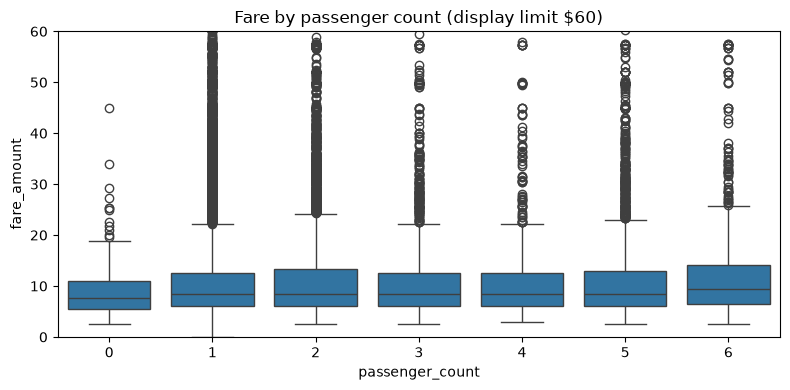

In [19]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df_clean,x="passenger_count",y="fare_amount"); plt.ylim(0,60); plt.title("Fare by passenger count (display limit $60)")
plt.tight_layout()
plt.show()

## Q2. Does car condition influence fare?

**Plot choice and reason:** Use Kruskal–Wallis as a nonparametric group comparison because fare is skewed. Association is not causation.

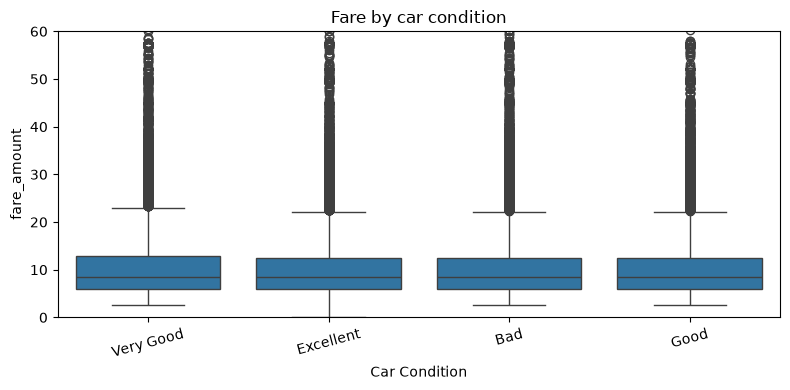

In [20]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df_clean,x="Car Condition",y="fare_amount"); plt.ylim(0,60); plt.xticks(rotation=15); plt.title("Fare by car condition")
plt.tight_layout()
plt.show()

In [21]:
groups = [g['fare_amount'].to_numpy() for _, g in df_clean.groupby('Car Condition')]
print('Kruskal-Wallis statistic, p-value:', kruskal(*groups))

Kruskal-Wallis statistic, p-value: KruskalResult(statistic=np.float64(7.391189514009584), pvalue=np.float64(0.060421168607775404))


## Q3. At what hour are fares typically highest?

**Plot choice and reason:** Check the ride count at each hour before interpreting the highest mean; route mix may explain differences.

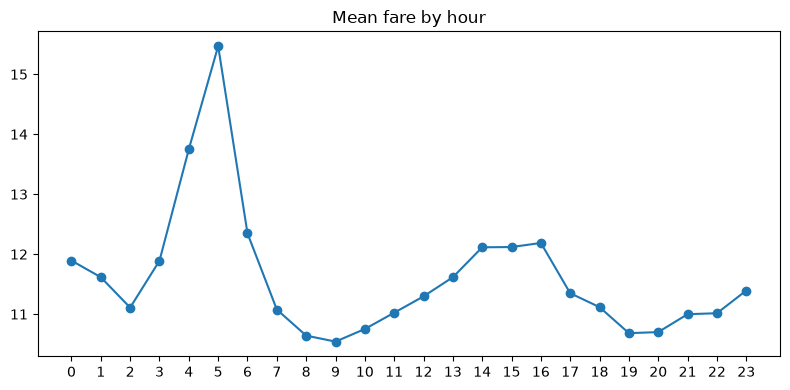

In [22]:
plt.figure(figsize=(8,4))
hourly=df_clean.groupby("hour").fare_amount.agg(["mean","count"]); plt.plot(hourly.index,hourly["mean"],marker="o"); plt.xticks(range(24)); plt.title("Mean fare by hour")
plt.tight_layout()
plt.show()

## Q4. Does traffic condition relate to fare?

**Plot choice and reason:** Compare full distributions and group sizes. If labels are synthetic or randomly assigned, a weak difference may not reflect real traffic effects.

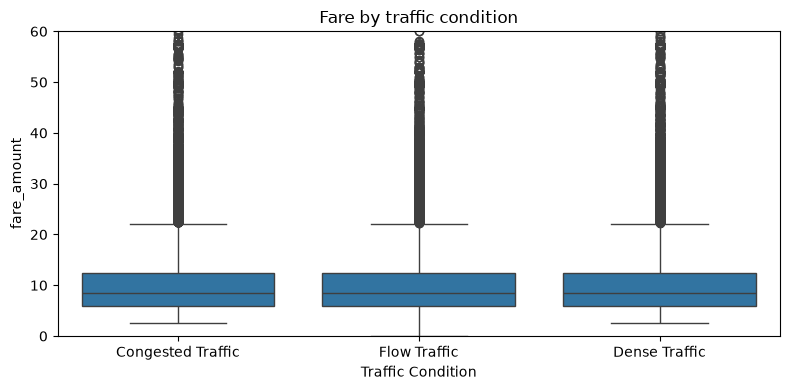

In [23]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df_clean,x="Traffic Condition",y="fare_amount"); plt.ylim(0,60); plt.title("Fare by traffic condition")
plt.tight_layout()
plt.show()

In [24]:
groups = [g['fare_amount'].to_numpy() for _, g in df_clean.groupby('Traffic Condition')]
print('Kruskal-Wallis statistic, p-value:', kruskal(*groups))

Kruskal-Wallis statistic, p-value: KruskalResult(statistic=np.float64(0.7429233491101074), pvalue=np.float64(0.6897254393569408))


## Q5. Is trip distance associated with fare?

**Plot choice and reason:** A positive pattern supports association, but claiming strongest predictor requires comparing other associations and model-based importance.

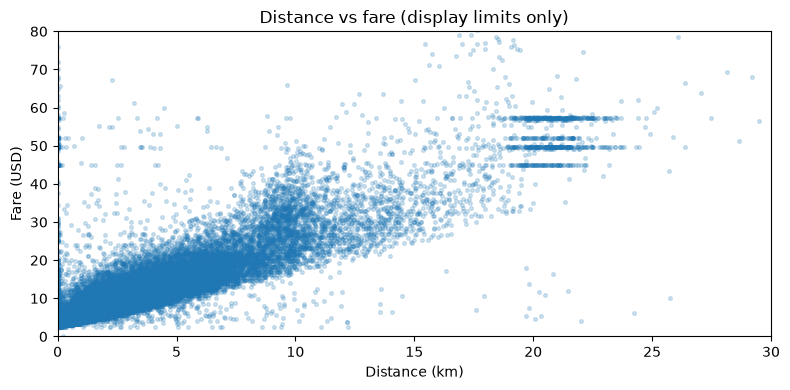

In [25]:
plt.figure(figsize=(8,4))
plt.scatter(df_clean.distance_recomputed_km,df_clean.fare_amount,s=7,alpha=.2); plt.xlim(0,30); plt.ylim(0,80); plt.xlabel("Distance (km)"); plt.ylabel("Fare (USD)"); plt.title("Distance vs fare (display limits only)")
plt.tight_layout()
plt.show()

In [26]:
print('Pearson:', pearsonr(df_clean.distance_recomputed_km, df_clean.fare_amount))
print('Spearman:', spearmanr(df_clean.distance_recomputed_km, df_clean.fare_amount))

Pearson: PearsonRResult(statistic=np.float64(0.8617499205080668), pvalue=np.float64(0.0))
Spearman: SignificanceResult(statistic=np.float64(0.8456355254541864), pvalue=np.float64(0.0))


## Q6. When are ride requests most frequent?

**Plot choice and reason:** This answers demand frequency, not which hour has the highest fare.

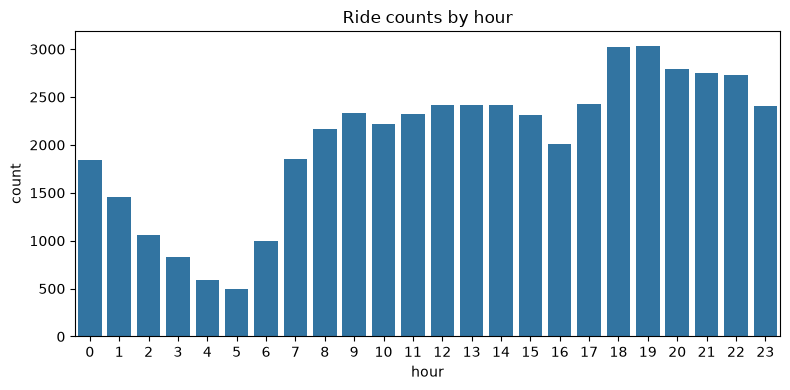

In [27]:
plt.figure(figsize=(8,4))
sns.countplot(data=df_clean,x="hour",order=range(24)); plt.title("Ride counts by hour")
plt.tight_layout()
plt.show()

## Q7. Does weather relate to trip distance?

**Plot choice and reason:** Use group counts and central distributions; the axis limit is for readability and does not remove rows.

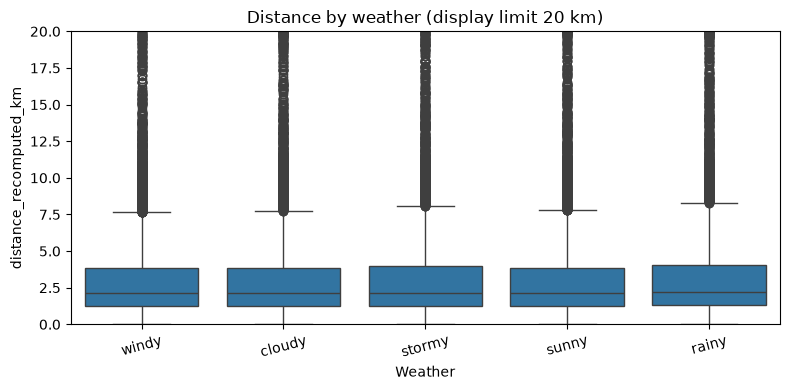

In [28]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df_clean,x="Weather",y="distance_recomputed_km"); plt.ylim(0,20); plt.xticks(rotation=15); plt.title("Distance by weather (display limit 20 km)")
plt.tight_layout()
plt.show()

## Q8. Are rides starting closer to airports more expensive?

**Plot choice and reason:** Treat this as a diagnostic only because the supplied airport-distance columns are suspect. Recompute from documented airport coordinates before making a conclusion.

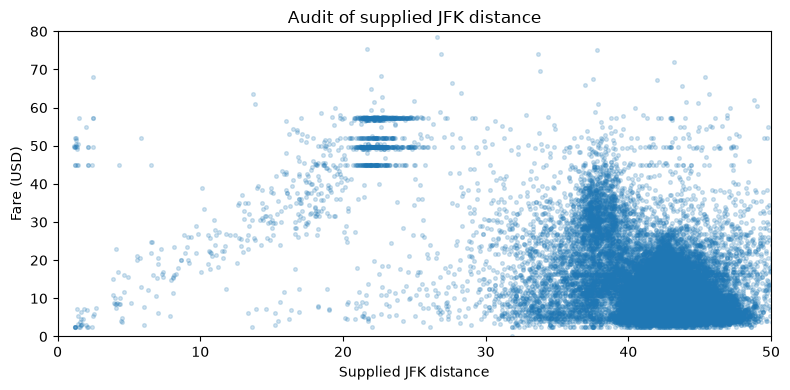

In [29]:
plt.figure(figsize=(8,4))
plt.scatter(df_clean.jfk_dist,df_clean.fare_amount,s=7,alpha=.2); plt.xlim(0,50); plt.ylim(0,80); plt.xlabel("Supplied JFK distance"); plt.ylabel("Fare (USD)"); plt.title("Audit of supplied JFK distance")
plt.tight_layout()
plt.show()

## 3. Additional questions and limitations

1. How does fare per kilometer vary by hour and year? Exclude or separately analyze zero-distance trips before division.
2. Where are valid pickup locations concentrated? Use a geographic scatterplot with degree-based coordinates.
3. Do zero-distance trips have different fares? Investigate rather than automatically dropping them.
4. Do weekend and weekday fare distributions differ?
5. How does fare change by year, and how well does a model trained on 2009–2014 generalize to 2015?

**Limitations:** 2015 covers only part of the year; categorical levels differ from the task brief; supplied airport/landmark distance columns need validation; plot axis limits do not mean data were clipped.

In [30]:
print('Fare summary:')
display(df_clean.fare_amount.describe(percentiles=[.5,.9,.95,.99]))
print('Mean fare by year:')
display(df_clean.groupby('year').fare_amount.agg(['mean','median','count']).round(2))
print('Categorical group counts:')
for c in ['Car Condition','Weather','Traffic Condition']:
    display(df_clean[c].value_counts().to_frame('count'))

Fare summary:


count    48897.000000
mean        11.340408
std          9.521839
min          0.010000
50%          8.500000
90%         20.500000
95%         30.330000
99%         52.000000
max        165.000000
Name: fare_amount, dtype: float64

Mean fare by year:


,mean,median,count
year,,,
2009,10.04,7.7,7593
2010,10.14,7.7,7441
2011,10.45,7.7,7617
2012,11.15,8.5,7810
2013,12.40,9.5,7663
2014,13.12,9.5,7389
2015,13.06,9.5,3384


Categorical group counts:


,count
Car Condition,
Good,12292
Bad,12228
Very Good,12190
Excellent,12187


,count
Weather,
sunny,9873
stormy,9837
rainy,9778
windy,9741
cloudy,9668


,count
Traffic Condition,
Flow Traffic,16338
Dense Traffic,16282
Congested Traffic,16277
